<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/main/notebooks/11_model_comparison_and_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 11 · Model comparison and selection
Loads the results of notebooks 01–10, compares all models on identical outer CV splits and selects the screening model.

1. Comparison table (CSV + displayed), sorted by ROC-AUC.
2. AUC bar chart with ± SD error bars and fold-level AUC distributions.
3. ROC curves of the top 4 models.
4. **Corrected resampled t-test** (Nadeau & Bengio, 2003) of the best model against every other model.
5. Model selection with justification.

## 1. Install missing packages
Colab already ships with numpy, pandas, scikit-learn, matplotlib, seaborn, XGBoost and LightGBM.
This cell only installs the packages that are missing in the current runtime, so it is safe to re-run.

In [ ]:
import importlib, subprocess, sys

REQUIRED = [
    ("scipy", "scipy"),
]
for import_name, pip_name in REQUIRED:
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
print("All required packages are available.")

All required packages are available.


## 2. Mount Google Drive and set the project folder
All notebooks share one project folder on Google Drive:

```
/content/drive/MyDrive/Dyscalculia_Stage1/
├── data/      ds004791_features.csv + shared configuration (features, X/y, CV splits)
├── results/   per-model metrics (.json) and out-of-fold probabilities (.csv)
├── models/    final models refit on all children (.joblib)
└── figures/   all plots
```
When the notebook is run outside Colab, a local `Dyscalculia_Stage1/` folder is used instead
(or the folder given by the `STAGE1_PROJECT_DIR` environment variable).

In [ ]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/Dyscalculia_Stage1'
except ImportError:  # running locally / outside Colab
    PROJECT_DIR = os.environ.get('STAGE1_PROJECT_DIR', os.path.abspath('Dyscalculia_Stage1'))

DATA_DIR    = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
MODELS_DIR  = os.path.join(PROJECT_DIR, 'models')
FIGURES_DIR = os.path.join(PROJECT_DIR, 'figures')
for d in (DATA_DIR, RESULTS_DIR, MODELS_DIR, FIGURES_DIR):
    os.makedirs(d, exist_ok=True)

CONFIG_PATH = os.path.join(DATA_DIR, 'stage1_config.joblib')
print('Project folder:', PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Dyscalculia_Stage1


## 3. Imports

In [ ]:
import glob, json, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_curve

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
PROPOSED = 'xgboost'
BASELINE = 'logistic_regression'
ALPHA = 0.05

## 4. Load all model results

In [ ]:
SKIP = {'model_selection'}
results = {}
for path in sorted(glob.glob(os.path.join(RESULTS_DIR, '*.json'))):
    name = os.path.splitext(os.path.basename(path))[0]
    if name in SKIP:
        continue
    with open(path) as f:
        r = json.load(f)
    if 'fold_metrics' in r:
        results[name] = r
print(f'Loaded {len(results)} models:', ', '.join(results))
assert PROPOSED in results, 'Run 02_xgboost.ipynb first.'

# All models must have been evaluated on the same 50 outer splits (paired comparison)
fold_tables = {n: pd.DataFrame(r['fold_metrics']).sort_values('split_id').reset_index(drop=True)
               for n, r in results.items()}
ref = fold_tables[PROPOSED]['split_id'].values
for n, t in fold_tables.items():
    assert np.array_equal(t['split_id'].values, ref), f'{n} was not evaluated on the shared splits'
DISPLAY = {n: r['display_name'] for n, r in results.items()}

Loaded 10 models: catboost, extra_trees, gradient_boosting, lightgbm, logistic_regression, mlp, random_forest, stacking_ensemble, svm_rbf, xgboost


## 5. Comparison table
Mean ± SD over the 50 outer test folds (threshold 0.5 for the threshold-dependent metrics).
`Pooled AUC` = AUC of the pooled out-of-fold predictions per repeat (mean over the 10 repeats).

In [ ]:
METRICS = ['auc', 'recall', 'specificity', 'balanced_accuracy', 'precision', 'f1']
LABELS = {'auc': 'ROC-AUC', 'recall': 'Sensitivity', 'specificity': 'Specificity',
          'balanced_accuracy': 'Balanced acc.', 'precision': 'Precision', 'f1': 'F1'}

rows = []
for n, r in results.items():
    row = {'model_name': n, 'Model': r['display_name']}
    for m in METRICS:
        row[f'{m}_mean'] = r['summary'][m]['mean']
        row[f'{m}_sd'] = r['summary'][m]['sd']
        row[LABELS[m]] = f"{r['summary'][m]['mean']:.3f} ± {r['summary'][m]['sd']:.3f}"
    row['Pooled AUC'] = np.mean(r['repeat_pooled_auc'])
    row['Runtime (min)'] = r['runtime_seconds'] / 60
    rows.append(row)

comparison = pd.DataFrame(rows).sort_values('auc_mean', ascending=False).reset_index(drop=True)
comparison.index = comparison.index + 1
comparison.index.name = 'Rank'
comparison.to_csv(os.path.join(RESULTS_DIR, 'model_comparison.csv'))
print('Saved ->', os.path.join(RESULTS_DIR, 'model_comparison.csv'))

display(comparison[['Model'] + [LABELS[m] for m in METRICS] + ['Pooled AUC', 'Runtime (min)']]
        .style.format({'Pooled AUC': '{:.3f}', 'Runtime (min)': '{:.1f}'}))

Saved -> /content/drive/MyDrive/Dyscalculia_Stage1/results/model_comparison.csv


,Model,ROC-AUC,Sensitivity,Specificity,Balanced acc.,Precision,F1,Pooled AUC,Runtime (min)
Rank,,,,,,,,,
1,MLP (neural network),0.750 ± 0.123,0.480 ± 0.195,0.810 ± 0.168,0.645 ± 0.102,0.716 ± 0.192,0.542 ± 0.158,0.735,4.0
2,SVM (RBF kernel),0.747 ± 0.137,0.117 ± 0.236,0.960 ± 0.110,0.539 ± 0.089,0.185 ± 0.349,0.132 ± 0.254,0.709,0.4
3,Extra Trees,0.744 ± 0.119,0.593 ± 0.182,0.743 ± 0.168,0.668 ± 0.118,0.671 ± 0.166,0.612 ± 0.149,0.723,13.0
4,Logistic Regression (baseline),0.741 ± 0.136,0.640 ± 0.179,0.693 ± 0.169,0.667 ± 0.122,0.636 ± 0.151,0.627 ± 0.141,0.718,0.3
5,XGBoost (proposed),0.739 ± 0.112,0.637 ± 0.164,0.713 ± 0.146,0.675 ± 0.114,0.648 ± 0.126,0.633 ± 0.128,0.724,1.6
6,Random Forest,0.732 ± 0.122,0.583 ± 0.173,0.735 ± 0.147,0.659 ± 0.106,0.655 ± 0.157,0.602 ± 0.131,0.718,14.7
7,LightGBM,0.687 ± 0.126,0.567 ± 0.184,0.701 ± 0.158,0.634 ± 0.123,0.609 ± 0.147,0.576 ± 0.150,0.674,1.3
8,Stacking (XGB + RF + SVM),0.684 ± 0.144,0.603 ± 0.187,0.665 ± 0.152,0.634 ± 0.106,0.595 ± 0.120,0.587 ± 0.130,0.672,25.9
9,Gradient Boosting (sklearn),0.673 ± 0.124,0.597 ± 0.178,0.661 ± 0.161,0.629 ± 0.101,0.593 ± 0.118,0.582 ± 0.125,0.664,3.9


## 6. ROC-AUC bar chart (mean ± SD) and fold-level distributions

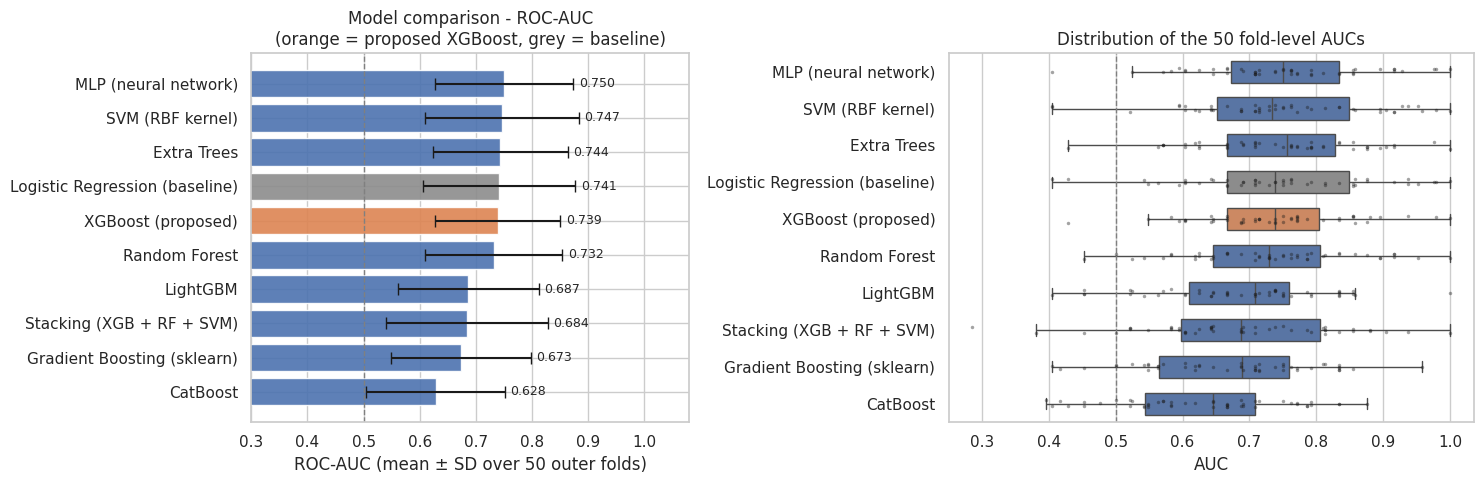

In [ ]:
order = comparison['model_name'].tolist()
colors = ['#DD8452' if n == PROPOSED else ('#8C8C8C' if n == BASELINE else '#4C72B0') for n in order]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.2]})
ax = axes[0]
ax.barh([DISPLAY[n] for n in order], comparison['auc_mean'], xerr=comparison['auc_sd'],
        color=colors, capsize=4, alpha=0.9)
for i, (m, s) in enumerate(zip(comparison['auc_mean'], comparison['auc_sd'])):
    ax.text(min(m + s + 0.01, 1.02), i, f'{m:.3f}', va='center', fontsize=9)
ax.axvline(0.5, ls='--', color='grey', lw=1)
ax.set_xlim(0.3, 1.08); ax.invert_yaxis()
ax.set_xlabel('ROC-AUC (mean ± SD over 50 outer folds)')
ax.set_title('Model comparison - ROC-AUC\n(orange = proposed XGBoost, grey = baseline)')

long = pd.concat([pd.DataFrame({'Model': DISPLAY[n], 'AUC': fold_tables[n]['auc']}) for n in order])
sns.boxplot(data=long, y='Model', x='AUC', order=[DISPLAY[n] for n in order], palette=colors, ax=axes[1],
            fliersize=0, width=0.6)
sns.stripplot(data=long, y='Model', x='AUC', order=[DISPLAY[n] for n in order], color='k', size=2.5,
              alpha=0.4, ax=axes[1])
axes[1].axvline(0.5, ls='--', color='grey', lw=1)
axes[1].set_title('Distribution of the 50 fold-level AUCs'); axes[1].set_ylabel('')
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, '11_auc_comparison.png'), dpi=200, bbox_inches='tight'); plt.show()

## 7. ROC curves of the top 4 models
Mean out-of-fold ROC curve over the 10 repeats (± 1 SD band) for the four best models by mean ROC-AUC.

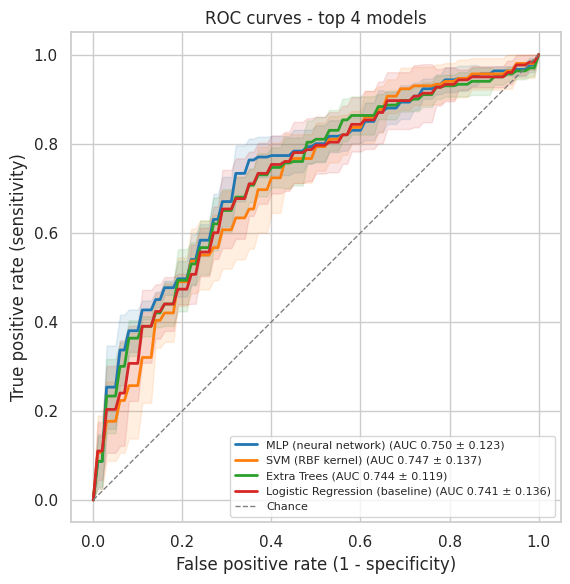

In [ ]:
def mean_roc(oof_df, grid=np.linspace(0, 1, 101)):
    tprs = []
    for _, d in oof_df.groupby('repeat'):
        fpr, tpr, _ = roc_curve(d['y_true'], d['prob_dd'])
        t = np.interp(grid, fpr, tpr); t[0] = 0.0
        tprs.append(t)
    tprs = np.array(tprs)
    return grid, tprs.mean(axis=0), tprs.std(axis=0, ddof=1)

top4 = order[:4]
fig, ax = plt.subplots(figsize=(6.5, 6))
for n, c in zip(top4, sns.color_palette('tab10', 4)):
    oof = pd.read_csv(os.path.join(RESULTS_DIR, f'{n}_oof.csv'))
    grid, m, s = mean_roc(oof)
    ax.plot(grid, m, lw=2, color=c,
            label=f"{DISPLAY[n]} (AUC {results[n]['summary']['auc']['mean']:.3f} ± {results[n]['summary']['auc']['sd']:.3f})")
    ax.fill_between(grid, np.clip(m - s, 0, 1), np.clip(m + s, 0, 1), color=c, alpha=0.12)
ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='Chance')
ax.set_xlabel('False positive rate (1 - specificity)'); ax.set_ylabel('True positive rate (sensitivity)')
ax.set_title('ROC curves - top 4 models'); ax.legend(loc='lower right', fontsize=8); ax.set_aspect('equal')
fig.tight_layout(); fig.savefig(os.path.join(FIGURES_DIR, '11_roc_top4.png'), dpi=200, bbox_inches='tight'); plt.show()

## 8. Corrected resampled t-test (Nadeau & Bengio, 2003)
The 50 fold scores of repeated CV are **not independent** — the training sets overlap heavily — so a standard
paired t-test is far too optimistic (it declares differences significant too often). Nadeau & Bengio's correction
inflates the variance by the test/train size ratio:

$$
t = \frac{\bar d}{\sqrt{\left(\frac{1}{J} + \frac{n_{test}}{n_{train}}\right)\hat\sigma_d^2}}, \qquad df = J - 1
$$

where $d_j$ is the AUC difference between two models on outer split $j$ (both models used the **same** split),
$J = 50$ and $n_{test}/n_{train} \approx 1/4$ for 5-fold CV. Holm–Bonferroni-adjusted p-values are also shown
because several comparisons are made.

In [ ]:
cfg = joblib.load(CONFIG_PATH)
n_test = np.mean([len(s['test_idx']) for s in cfg['outer_splits']])
n_train = np.mean([len(s['train_idx']) for s in cfg['outer_splits']])
RATIO = n_test / n_train
print(f'n_test / n_train = {n_test:.1f} / {n_train:.1f} = {RATIO:.3f}')


def corrected_resampled_ttest(a, b, ratio=RATIO):
    """Nadeau & Bengio corrected resampled t-test for paired CV scores a, b (same splits)."""
    d = np.asarray(a) - np.asarray(b)
    J = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return d.mean(), np.nan, 1.0
    t = d.mean() / np.sqrt((1 / J + ratio) * var)
    p = 2 * stats.t.sf(abs(t), df=J - 1)
    return d.mean(), t, p


def holm(pvals):
    """Holm-Bonferroni step-down adjusted p-values."""
    p = np.asarray(pvals, float)
    idx = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(idx):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj


def compare_against(reference):
    rows = []
    for n in order:
        if n == reference:
            continue
        diff, t, p = corrected_resampled_ttest(fold_tables[reference]['auc'], fold_tables[n]['auc'])
        naive_p = stats.ttest_rel(fold_tables[reference]['auc'], fold_tables[n]['auc']).pvalue
        rows.append({'Compared model': DISPLAY[n], 'model_name': n, 'AUC difference': diff, 't (corrected)': t,
                     'p (corrected)': p, 'p (naive paired t-test)': naive_p})
    out = pd.DataFrame(rows)
    out['p (Holm)'] = holm(out['p (corrected)'])
    out['Significant (Holm, 0.05)'] = out['p (Holm)'] < ALPHA
    return out


BEST = order[0]
tests_best = compare_against(BEST)
tests_best.to_csv(os.path.join(RESULTS_DIR, f'ttest_{BEST}_vs_all.csv'), index=False)
print(f'Best model by mean ROC-AUC: {DISPLAY[BEST]}  -> tested against every other model')
display(tests_best.drop(columns='model_name').style.format(
    {'AUC difference': '{:+.3f}', 't (corrected)': '{:.2f}', 'p (corrected)': '{:.4f}',
     'p (naive paired t-test)': '{:.4f}', 'p (Holm)': '{:.4f}'}))
print('Note how much smaller the naive p-values are - this is why the correction is needed.')

n_test / n_train = 13.6 / 54.4 = 0.250
Best model by mean ROC-AUC: MLP (neural network)  -> tested against every other model


,Compared model,AUC difference,t (corrected),p (corrected),p (naive paired t-test),p (Holm),"Significant (Holm, 0.05)"
0,SVM (RBF kernel),+0.004,0.10,0.9174,0.7032,1.0000,False
1,Extra Trees,+0.007,0.32,0.7523,0.2493,1.0000,False
2,Logistic Regression (baseline),+0.009,0.32,0.7509,0.2464,1.0000,False
3,XGBoost (proposed),+0.012,0.25,0.8009,0.3560,1.0000,False
4,Random Forest,+0.018,0.49,0.6262,0.0778,1.0000,False
5,LightGBM,+0.064,1.16,0.2508,0.0001,1.0000,False
6,Stacking (XGB + RF + SVM),+0.066,1.02,0.3123,0.0005,1.0000,False
7,Gradient Boosting (sklearn),+0.077,1.46,0.1503,0.0000,1.0000,False
8,CatBoost,+0.122,2.16,0.0361,0.0000,0.3247,False


Note how much smaller the naive p-values are - this is why the correction is needed.


If the best model is not the proposed XGBoost, we also test **XGBoost against every other model** for completeness.

In [ ]:
if BEST != PROPOSED:
    tests_xgb = compare_against(PROPOSED)
    tests_xgb.to_csv(os.path.join(RESULTS_DIR, f'ttest_{PROPOSED}_vs_all.csv'), index=False)
    display(tests_xgb.drop(columns='model_name').style.format(
        {'AUC difference': '{:+.3f}', 't (corrected)': '{:.2f}', 'p (corrected)': '{:.4f}',
         'p (naive paired t-test)': '{:.4f}', 'p (Holm)': '{:.4f}'}))
else:
    tests_xgb = tests_best
    print('XGBoost is the best model - see the table above.')

,Compared model,AUC difference,t (corrected),p (corrected),p (naive paired t-test),p (Holm),"Significant (Holm, 0.05)"
0,MLP (neural network),-0.012,-0.25,0.8009,0.3560,1.0000,False
1,SVM (RBF kernel),-0.008,-0.15,0.8848,0.5949,1.0000,False
2,Extra Trees,-0.005,-0.12,0.9015,0.6495,1.0000,False
3,Logistic Regression (baseline),-0.003,-0.05,0.9585,0.8484,1.0000,False
4,Random Forest,+0.007,0.23,0.8214,0.4083,1.0000,False
5,LightGBM,+0.052,1.24,0.2198,0.0000,1.0000,False
6,Stacking (XGB + RF + SVM),+0.054,1.04,0.3019,0.0004,1.0000,False
7,Gradient Boosting (sklearn),+0.065,1.74,0.0885,0.0000,0.7077,False
8,CatBoost,+0.111,2.82,0.0069,0.0000,0.0617,False


## 9. Model selection
**Pre-specified decision rule** (fixed before looking at the results):
1. Primary criterion: highest mean ROC-AUC on the nested CV.
2. If the proposed XGBoost is **not significantly worse** than the best model (corrected t-test, p ≥ 0.05),
   XGBoost is selected, because it additionally provides (a) exact and fast TreeSHAP explanations per child —
   required for teachers and parents in the explainable screening tool — (b) native handling of missing task data and
   (c) a single model that is easier to deploy and audit than a stacked ensemble.
3. Otherwise the significantly better model is selected.

We also report honestly whether the simple logistic-regression baseline is significantly worse — with 68 children,
comparable performance of a simple model is a realistic outcome and an important finding in itself.

In [ ]:
def fmt(n):
    s = results[n]['summary']
    return f"{DISPLAY[n]} (AUC {s['auc']['mean']:.3f} ± {s['auc']['sd']:.3f})"

lines = []
if BEST == PROPOSED:
    selected = PROPOSED
    lines.append(f'{fmt(PROPOSED)} achieved the highest mean ROC-AUC of all {len(order)} models.')
else:
    p_vs_xgb = tests_best.set_index('model_name').loc[PROPOSED, 'p (corrected)']
    if p_vs_xgb >= ALPHA:
        selected = PROPOSED
        lines.append(f'{fmt(BEST)} had the highest mean ROC-AUC, but the difference to {fmt(PROPOSED)} is '
                     f'not statistically significant (corrected resampled t-test p = {p_vs_xgb:.3f}).')
        lines.append('Following the pre-specified rule, XGBoost is selected for its exact TreeSHAP explanations, '
                     'native missing-value handling and simpler deployment.')
    else:
        selected = BEST
        lines.append(f'{fmt(BEST)} is significantly better than {fmt(PROPOSED)} '
                     f'(corrected p = {p_vs_xgb:.3f}) and is therefore selected.')

# Proposed model vs baseline
xgb_vs_lr = tests_xgb.set_index('model_name').loc[BASELINE] if BASELINE in tests_xgb['model_name'].values else None
if xgb_vs_lr is not None:
    verdict = 'significantly better than' if xgb_vs_lr['p (corrected)'] < ALPHA else 'not significantly different from'
    lines.append(f"XGBoost vs the logistic-regression baseline: AUC difference {xgb_vs_lr['AUC difference']:+.3f}, "
                 f"corrected p = {xgb_vs_lr['p (corrected)']:.3f} -> XGBoost is {verdict} the baseline.")

s = results[selected]['summary']
lines.append(f"Selected model screening profile: sensitivity {s['recall']['mean']:.3f} ± {s['recall']['sd']:.3f}, "
             f"specificity {s['specificity']['mean']:.3f} ± {s['specificity']['sd']:.3f}, "
             f"balanced accuracy {s['balanced_accuracy']['mean']:.3f} ± {s['balanced_accuracy']['sd']:.3f}.")

print(f'SELECTED MODEL: {DISPLAY[selected]}\n')
for l in lines:
    print('-', l)

selection = {'selected_model': selected, 'selected_display_name': DISPLAY[selected], 'best_by_auc': BEST,
             'decision_rule': 'highest mean AUC; proposed XGBoost kept unless significantly worse '
                              '(Nadeau-Bengio corrected resampled t-test, alpha=0.05)',
             'justification': lines, 'ranking': order}
with open(os.path.join(RESULTS_DIR, 'model_selection.json'), 'w') as f:
    json.dump(selection, f, indent=2)
print('\nSaved ->', os.path.join(RESULTS_DIR, 'model_selection.json'))

SELECTED MODEL: XGBoost (proposed)

- MLP (neural network) (AUC 0.750 ± 0.123) had the highest mean ROC-AUC, but the difference to XGBoost (proposed) (AUC 0.739 ± 0.112) is not statistically significant (corrected resampled t-test p = 0.801).
- Following the pre-specified rule, XGBoost is selected for its exact TreeSHAP explanations, native missing-value handling and simpler deployment.
- XGBoost vs the logistic-regression baseline: AUC difference -0.003, corrected p = 0.959 -> XGBoost is not significantly different from the baseline.
- Selected model screening profile: sensitivity 0.637 ± 0.164, specificity 0.713 ± 0.146, balanced accuracy 0.675 ± 0.114.

Saved -> /content/drive/MyDrive/Dyscalculia_Stage1/results/model_selection.json


## Limitations to mention to the panel
* **Small sample (n = 68):** fold-level SDs are large; differences of a few AUC points between models are within noise.
* **Single dataset / single site:** performance must be confirmed on an external sample before use in schools.
* **Screening, not diagnosis:** the model flags *risk*; a positive screen should lead to assessment by a specialist.
* The 0.5 threshold is a default; for screening, a threshold favouring sensitivity can be chosen in a later stage.